# 供应链与资源配置 · 双供应商运输分配

QuantumBridge / 工业优化 / 中文可执行案例

**执行状态：仅本地运行；未提交夸父真机；新增云任务 0。**

面向了解 Python 的读者：完成建模、检查中间结果、运行原生电路或明确标记的经典密码步骤，并与独立基线核对。

**范围边界：** 单期两对两不可分割运输模型，不包含库存、缺货动态、多周期产能或真实供应链系统接口。

## 1. 原理与计算对象

两供应商各有一个不可拆分货运单位，两客户各需一个单位。四个二元变量表示 S0-C0、S0-C1、S1-C0、S1-C1 的运输选择。成本矩阵为 [[2,5],[4,1]]。
目标 $\sum c_{ij}x_{ij}$，客户需求用 $(\sum_i x_{ij}-1)^2$ 罚项，供应容量用 $\max(0,\sum_jx_{ij}-1)^2$ 罚项。罚系数 20，全部 16 个真值检查罚项是否足够。

这是单期匹配运输，不是库存或跨期协同。经典完全枚举提供独立决策基线；QAOA 的最终输出须恢复运输矩阵，再检查每个供应行和客户列。

## 2. 实现步骤

1. 输入合成运输成本、两供应容量和两客户需求。
2. 枚举四条边，恢复运输矩阵和供需合计。
3. 计算运输费、缺额与超额罚项，确定最优成本。
4. 构造原生对角成本演化及混合门，优化参数。
5. 采样、还原运输矩阵并报告成本差与可行率。

## 3. 环境与可复现参数

依赖本仓库、NumPy、Matplotlib、Jupyter；安全案例还使用已安装的 OpenSSL / cryptography。模型和电路不调用 Qiskit 或 PennyLane。Notebook 保留真实执行输出，Python 解释器版本会在下方打印。

In [1]:
import os, sys, json
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
root = next((p for p in [Path(os.environ.get("QB_REPO_ROOT", ".")).resolve(), *Path.cwd().resolve().parents] if (p/"quantumbridge").is_dir() and (p/"scripts").is_dir()), None)
if root is None:
    raise RuntimeError("Run from the QuantumBridge checkout or set QB_REPO_ROOT.")
sys.path.insert(0, str(root)); sys.path.insert(0, str(root/"scripts"))
from IPython.display import display, HTML
from application_notebook_support import STYLE, show_json, intermediate_tables, plot_intermediate, show_measurements
from quantumbridge.applications.common import run_local_case
display(HTML(STYLE))
SHOTS, SEED = 1024, 20261023
print("Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit:", SHOTS)

print(sys.version)
from quantumbridge.finance.kernels import labels
from quantumbridge.applications.common import optimization_case

Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit: 1024
3.12.6 (v3.12.6:a4a2d2b0d85, Sep  6 2024, 16:08:03) [Clang 13.0.0 (clang-1300.0.29.30)]


## 4. 完整应用建模代码

以下是本案例实际执行的应用函数，不是伪代码。底层电路、映射、演化与采样复用仓库原生接口；优化类的共享辅助函数也位于 `quantumbridge/applications/common.py`。

In [2]:
def supply_case():
    candidates = []
    cost = [2, 5, 4, 1]
    for bits in labels(4):
        x = list(map(int, bits))
        supplied = [x[0] + x[1], x[2] + x[3]]
        received = [x[0] + x[2], x[1] + x[3]]
        violation = sum((value - 1) ** 2 for value in received) + sum(
            max(0, value - 1) ** 2 for value in supplied
        )
        objective = sum(c * b for c, b in zip(cost, x))
        candidates.append(
            {
                "bitstring": bits,
                "shipping_matrix": [x[:2], x[2:]],
                "supplier_load": supplied,
                "customer_received": received,
                "violations": violation,
                "feasible": violation == 0,
                "objective": objective,
                "penalized_cost": objective + 20 * violation,
            }
        )
    return optimization_case(
        "supply-chain",
        "industry",
        "Two-supplier two-customer allocation",
        {
            "shipping_cost": [cost[:2], cost[2:]],
            "supplier_capacity": [1, 1],
            "customer_demand": [1, 1],
            "bit_order": ["S0-C0", "S0-C1", "S1-C0", "S1-C1"],
            "penalty": 20,
            "units": "one indivisible shipment per selected edge; synthetic costs",
        },
        candidates,
    )


In [3]:
case = supply_case()
show_json(case.inputs)

## 5. 中间结果与效果

下方完整列出模型候选、优化轨迹或物理中间量。图中的 exact / classical 是经典计算基线，不冒充量子实验。图表使用英文坐标避免本机中文字体缺失，解释与表格保留中文。

bitstring,shipping_matrix,supplier_load,customer_received,violations,feasible,objective,penalized_cost
0000,"[[0, 0], [0, 0]]","[0, 0]","[0, 0]",2,False,0,40
0001,"[[0, 0], [0, 1]]","[0, 1]","[0, 1]",1,False,1,21
0010,"[[0, 0], [1, 0]]","[0, 1]","[1, 0]",1,False,4,24
0011,"[[0, 0], [1, 1]]","[0, 2]","[1, 1]",1,False,5,25
0100,"[[0, 1], [0, 0]]","[1, 0]","[0, 1]",1,False,5,25
0101,"[[0, 1], [0, 1]]","[1, 1]","[0, 2]",2,False,6,46
0110,"[[0, 1], [1, 0]]","[1, 1]","[1, 1]",0,True,9,9
0111,"[[0, 1], [1, 1]]","[1, 2]","[1, 2]",2,False,10,50
1000,"[[1, 0], [0, 0]]","[1, 0]","[1, 0]",1,False,2,22
1001,"[[1, 0], [0, 1]]","[1, 1]","[1, 1]",0,True,3,3


improvement,expected_penalized_cost,gamma,beta
0,36,0,0
1,36,0,0.24166097
2,36,0,1.9332878
3,33.826693,0.78539816,1.2083049
4,32.398643,0.78539816,2.4166097
5,29.766775,0.78539816,2.6582707
6,24.719806,1.5707963,2.6582707
7,21.327324,2.3561945,2.6582707
8,19.819541,3.1415927,2.6582707
9,19.741012,3.3415927,2.6582707


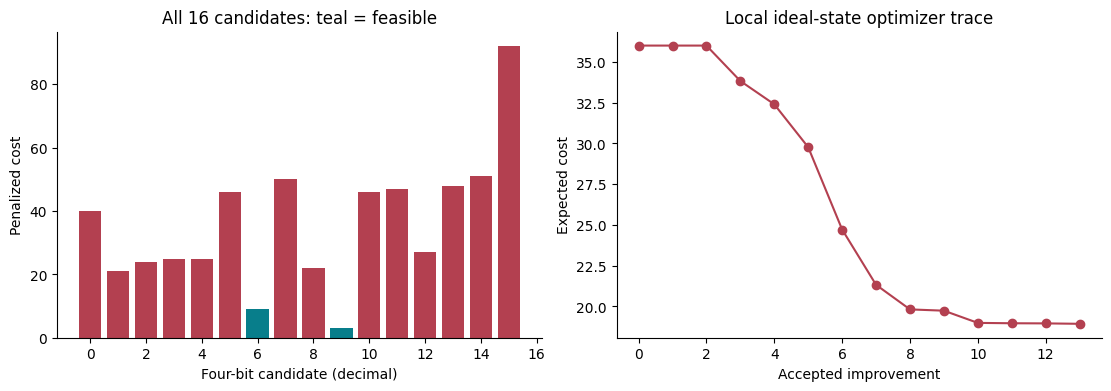

In [4]:
intermediate_tables(case)
plot_intermediate(case)

## 6. 实际运行与最终效果

模拟器使用固定种子逐次采样，counts 总数必须等于 shots。估计标准误由实际样本方差计算；近似 95% 区间可写作 estimate ± 1.96 × SE，但小样本及零计数需另用适当区间。本例不把这些区间当成硬件精度验收。

experiment,qubits,gates,shots,seed
qaoa,4,26,1024,20261023


observable,estimate,standard_error,ideal_reference
qaoa,19.607422,0.3999163,18.93606


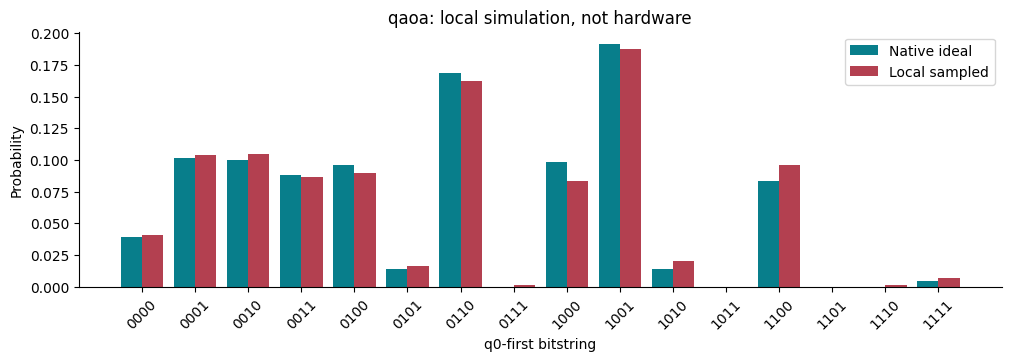

experiment,counts
qaoa,"{""0011"": 89, ""0110"": 166, ""1100"": 98, ""0010"": 107, ""1001"": 192, ""0100"": 92, ""0101"": 17, ""0001"": 106, ""1000"": 85, ""0000"": 42, ""1010"": 21, ""1111"": 7, ""1110"": 1, ""0111"": 1}"


In [5]:
evidence = run_local_case(case, shots=SHOTS, seed=SEED)
show_measurements(case, evidence)

## 7. 可检查的电路输出

导出全部业务电路的 OpenQASM 2，位串采用 q0-first。可导出不等于已通过夸父设备门集、耦合图、深度和精度验收；本批不会访问凭据、提交任务或消耗金融额度。纯经典案例没有伪造量子电路。

In [6]:
for name, result in evidence['experiments'].items():
    print('\n---', name, '---\n'+result['openqasm2'])
if not evidence['experiments']:
    print('Classical cryptography / security workflow: no quantum circuit.')


--- qaoa ---
OPENQASM 2.0;
include "qelib1.inc";
qreg q[4];
creg c[4];
h q[0];
h q[1];
h q[2];
h q[3];
cx q[0],q[1];
rz(0.38388681501008914) q[1];
cx q[0],q[1];
cx q[0],q[2];
rz(0.76777363002017818) q[2];
cx q[0],q[2];
rz(-0.46066417801210691) q[0];
cx q[1],q[3];
rz(0.76777363002017818) q[3];
cx q[1],q[3];
rz(-0.57583022251513349) q[1];
cx q[2],q[3];
rz(0.38388681501008903) q[3];
cx q[2],q[3];
rz(-0.53744154101412478) q[2];
rz(-0.42227549651109803) q[3];
rz(2.5336529790665874) q[0];
u1(-2.5336529790665874) q[0];
rx(5.4665414137673425) q[0];
rx(5.4665414137673425) q[1];
rx(5.4665414137673425) q[2];
rx(5.4665414137673425) q[3];
measure q[0] -> c[0];
measure q[1] -> c[1];
measure q[2] -> c[2];
measure q[3] -> c[3];



## 8. 结果解释、复做与非目标

正确最优运输是 S0→C0 和 S1→C1，成本 3。任何低成本但客户没收到货的串都应判为不可行，不进入最终决策。

单期两对两不可分割运输模型，不包含库存、缺货动态、多周期产能或真实供应链系统接口。

练习：对已有电路将 shots 改为 2048，比较估计与标准误；如果是纯经典密码案例，比较密文/公钥大小和篡改检测结果。安全案例的私钥只在临时目录或内存中存在，不输出密钥。重新执行此 Notebook 仍然只运行本地代码。

In [7]:
repeat = run_local_case(case, shots=2048, seed=SEED+100)
show_json({'execution_mode':repeat['execution_mode'], 'estimates':repeat['estimates'], 'new_cloud_tasks':repeat['new_cloud_tasks']})
assert all(sum(row['counts'].values()) == 2048 for row in repeat['experiments'].values())
assert repeat['new_cloud_tasks'] == 0
assert repeat['hardware_access'] is False

In [8]:
artifact = {'inputs':case.inputs, 'intermediate':case.intermediate, 'reference':case.reference, 'evidence':evidence}
path = root/'output/jupyter-notebook/industry/02_supply-chain_evidence.json'
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(artifact, ensure_ascii=False, indent=2), encoding='utf-8')
print('Evidence:', path.name)

Evidence: 02_supply-chain_evidence.json


## 9. 参考与责任边界

独立编写应用代码，未复制上游 SDK 实现或第三方教程代码；下列资料用于数学与接口背景。

- [Qiskit Optimization 建模概念](https://qiskit-community.github.io/qiskit-optimization/tutorials/01_quadratic_program.html)

本案例不是生产支持证书，也不代表 Qiskit / PennyLane 全量替代已经完成。